## LangGraph persistence and human-in-the-loop

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mzarnecki/course_llm_agent_apps_with_langchain_and_langgraph/blob/main/notebooks/en/8_5_LangGraph_persistence_and_HITL_en.ipynb)

| | |
|---|---|
| 🎯 **What you'll learn** | Checkpointing (InMemorySaver, SqliteSaver), state history, recovery after a crash, time travel (replay and fork), and human-in-the-loop with `interrupt()` and `Command(resume=...)`: approve / edit / reject, validation loops, interrupts inside tools and parallel interrupts. |
| 🔑 **API keys** | `OPENAI_API_KEY` |
| 💲 **API cost** | very low – a few short requests |
| ⏱️ **Run time** | < 1 min |

### Install libraries

In [1]:
# Install this notebook's direct dependencies.
# Skipped when pip is missing, e.g. in the `uv sync` environment, which already has them (see README).
import importlib.util
if importlib.util.find_spec("pip"):
    %pip install -qU langgraph langgraph-checkpoint-sqlite langchain langchain-openai pandas python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.

Note: you may need to restart the kernel to use updated packages.


In [2]:
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(model="gpt-6.1-terra", reasoning_effort="none")

## 1. Checkpointing – how LangGraph remembers

When a graph is compiled with a **checkpointer**, LangGraph saves a snapshot of the state (a **checkpoint**) after every step (*super-step*). Checkpoints are grouped into **threads** identified by `thread_id`.

```
invoke(input, thread_id="order-1")
   │
   ▼
[validate] ──► 💾 ──► [price] ──► 💾 ──► [discount] ──► 💾
             checkpoint          checkpoint             checkpoint
```

This one mechanism gives us everything in this notebook:

| Capability | What it needs from checkpoints |
|---|---|
| Conversation memory | continue the same thread with a new message |
| Fault tolerance | resume from the last successful step after a crash |
| Time travel | replay or fork from any past checkpoint |
| Human-in-the-loop | pause the graph, wait (seconds or days), resume |

| Concept | Meaning |
|---|---|
| `thread_id` | id of one conversation / process / case |
| checkpoint | snapshot of the state after a super-step (`StateSnapshot`) |
| checkpointer | storage backend: `InMemorySaver`, `SqliteSaver`, `PostgresSaver`, … |

We start with a deterministic order-processing graph – no LLM needed to understand persistence.

In [3]:
import operator
from typing import Annotated, TypedDict

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph


class OrderState(TypedDict, total=False):
    item: str
    quantity: int
    total: float
    log: Annotated[list[str], operator.add]  # reducer: new entries are appended


PRICES = {"keyboard": 120.0, "mouse": 40.0, "monitor": 900.0}


def validate(state: OrderState) -> OrderState:
    if state["item"] not in PRICES:
        raise ValueError(f"unknown item: {state['item']}")
    return {"log": [f"validated {state['quantity']} x {state['item']}"]}


def price(state: OrderState) -> OrderState:
    total = PRICES[state["item"]] * state["quantity"]
    return {"total": total, "log": [f"priced: {total:.2f}"]}


def discount(state: OrderState) -> OrderState:
    total = round(state["total"] * (0.9 if state["total"] > 500 else 1.0), 2)
    return {"total": total, "log": [f"after discount: {total:.2f}"]}


def build_order_graph(checkpointer):
    builder = StateGraph(OrderState)
    builder.add_node(validate)
    builder.add_node(price)
    builder.add_node(discount)
    builder.add_edge(START, "validate")
    builder.add_edge("validate", "price")
    builder.add_edge("price", "discount")
    builder.add_edge("discount", END)
    return builder.compile(checkpointer=checkpointer)


order_graph = build_order_graph(InMemorySaver())
config = {"configurable": {"thread_id": "order-1"}}
order_graph.invoke({"item": "keyboard", "quantity": 5}, config)

{'item': 'keyboard',
 'quantity': 5,
 'total': 540.0,
 'log': ['validated 5 x keyboard', 'priced: 600.00', 'after discount: 540.00']}

### Current state and state history

`get_state` returns the latest `StateSnapshot`; `get_state_history` returns all checkpoints of the thread, **newest first**.

In [4]:
import pandas as pd

snapshot = order_graph.get_state(config)
print("values:", snapshot.values)
print("next:  ", snapshot.next)  # () = the graph has finished


def history_table(graph, config) -> pd.DataFrame:
    return pd.DataFrame(
        {
            "step": s.metadata["step"],
            "source": s.metadata["source"],
            "next": s.next,
            "total": s.values.get("total"),
            "checkpoint_id": s.config["configurable"]["checkpoint_id"][-8:],
        }
        for s in graph.get_state_history(config)
    )


history_table(order_graph, config)

values: {'item': 'keyboard', 'quantity': 5, 'total': 540.0, 'log': ['validated 5 x keyboard', 'priced: 600.00', 'after discount: 540.00']}
next:   ()


,step,source,next,total,checkpoint_id
0,3,loop,(),540.0,c0fa442c
1,2,loop,"(discount,)",600.0,74f1561b
2,1,loop,"(price,)",NaN,43cdf8ac
3,0,loop,"(validate,)",NaN,3341a544
4,-1,input,"(__start__,)",NaN,355ba6d0


Threads are fully isolated – a different `thread_id` is a different order:

In [5]:
order_graph.invoke({"item": "mouse", "quantity": 2}, {"configurable": {"thread_id": "order-2"}})
for thread in ["order-1", "order-2"]:
    print(thread, "->", order_graph.get_state({"configurable": {"thread_id": thread}}).values["log"])

order-1 -> ['validated 5 x keyboard', 'priced: 600.00', 'after discount: 540.00']
order-2 -> ['validated 2 x mouse', 'priced: 80.00', 'after discount: 80.00']


## 2. Durable execution – SqliteSaver and recovery after a crash

`InMemorySaver` disappears with the Python process. For real applications the checkpointer writes to a database: `SqliteSaver` (local, single process) or `PostgresSaver` (production). The API is identical.

The scenario: an order pipeline whose **payment API is down**. The graph crashes in `charge_card`. We then "restart the application" – new DB connection, new graph object – and continue the same thread. Thanks to the checkpoints, **steps that already succeeded are not executed again** (no double stock reservation!).

`durability="sync"` makes LangGraph write each checkpoint before starting the next step (the safest mode; the default `"async"` writes in the background, `"exit"` only at the end).

In [6]:
import sqlite3
import tempfile
from collections import Counter
from pathlib import Path

from langgraph.checkpoint.sqlite import SqliteSaver

DB_PATH = Path(tempfile.gettempdir()) / "langgraph_checkpoints.sqlite"
for suffix in ("", "-wal", "-shm"):  # stale WAL/shm files cause "disk I/O error"
    Path(f"{DB_PATH}{suffix}").unlink(missing_ok=True)  # start the demo from a clean database

calls = Counter()  # how many times each node really ran
payment_api_up = False


class PaymentState(TypedDict, total=False):
    order_id: str
    log: Annotated[list[str], operator.add]


def reserve_stock(state: PaymentState) -> PaymentState:
    calls["reserve_stock"] += 1
    return {"log": ["stock reserved"]}


def charge_card(state: PaymentState) -> PaymentState:
    calls["charge_card"] += 1
    if not payment_api_up:
        raise ConnectionError("payment API unavailable")
    return {"log": ["card charged"]}


def send_confirmation(state: PaymentState) -> PaymentState:
    calls["send_confirmation"] += 1
    return {"log": ["confirmation e-mail sent"]}


def build_payment_graph(checkpointer):
    builder = StateGraph(PaymentState)
    builder.add_node(reserve_stock)
    builder.add_node(charge_card)
    builder.add_node(send_confirmation)
    builder.add_edge(START, "reserve_stock")
    builder.add_edge("reserve_stock", "charge_card")
    builder.add_edge("charge_card", "send_confirmation")
    builder.add_edge("send_confirmation", END)
    return builder.compile(checkpointer=checkpointer)


config = {"configurable": {"thread_id": "order-1001"}}

# --- first application run
connection = sqlite3.connect(DB_PATH, check_same_thread=False)
graph = build_payment_graph(SqliteSaver(connection))
try:
    graph.invoke({"order_id": "1001"}, config, durability="sync")
except ConnectionError as error:
    print("💥 crashed:", error)
print("next step saved in DB:", graph.get_state(config).next)
connection.close()  # the process "dies"

💥 crashed: payment API unavailable
next step saved in DB: ('charge_card',)


In [7]:
# --- application restart: new connection, new graph object, the payment API is back
payment_api_up = True
connection = sqlite3.connect(DB_PATH, check_same_thread=False)
graph = build_payment_graph(SqliteSaver(connection))

result = graph.invoke(None, config, durability="sync")  # None = continue from the last checkpoint
print("log:  ", result["log"])
print("calls:", dict(calls))
assert calls["reserve_stock"] == 1  # stock was NOT reserved twice

log:   ['stock reserved', 'card charged', 'confirmation e-mail sent']
calls: {'reserve_stock': 1, 'charge_card': 2, 'send_confirmation': 1}


💡 In production add a `RetryPolicy` to flaky nodes (`builder.add_node(charge_card, retry_policy=RetryPolicy(max_attempts=3))`) – retries handle short glitches, checkpoints handle long outages and restarts.

## 3. Time travel – replay and fork

Every checkpoint has its own `checkpoint_id`, so we can go back in time:

- **Replay** – `invoke(None, past_config)` re-runs the graph from a past checkpoint.
- **Fork** – `update_state(past_config, new_values)` creates a new checkpoint branching off the past one, with modified state; the graph continues from there. The original history stays untouched.

Typical uses: debugging ("what if the LLM had returned something else?"), correcting a wrong step, exploring alternatives.

In [8]:
config = {"configurable": {"thread_id": "order-1"}}

# the checkpoint just before `discount` ran (history is newest first)
before_discount = next(s for s in order_graph.get_state_history(config) if s.next == ("discount",))
print("state before discount:", before_discount.values["total"])

# FORK: what if the customer had ordered 20 keyboards?
fork_config = order_graph.update_state(before_discount.config, {"quantity": 20, "total": 20 * PRICES["keyboard"]})
forked = order_graph.invoke(None, fork_config)
print("forked total:         ", forked["total"])

history_table(order_graph, config)

state before discount: 600.0
forked total:          2160.0


,step,source,next,total,checkpoint_id
0,4,loop,(),2160.0,08ec0455
1,3,update,"(discount,)",2400.0,3bdb2003
2,3,loop,(),540.0,c0fa442c
3,2,loop,"(discount,)",600.0,74f1561b
4,1,loop,"(price,)",NaN,43cdf8ac
5,0,loop,"(validate,)",NaN,3341a544
6,-1,input,"(__start__,)",NaN,355ba6d0


The history now contains both branches: the original run (total 540.0) and the fork (`source = update` followed by the new `discount` step, total 2160.0). The latest checkpoint of the thread is the fork.

## 4. Human-in-the-loop with `interrupt()`

`interrupt(payload)` called inside a node **pauses the graph**, saves a checkpoint and returns the `payload` to the caller. The human can answer immediately or a week later – the state waits in the checkpointer. `Command(resume=value)` restarts the paused node and this time `interrupt()` **returns** `value`.

```
draft_decision ──► human_review ──interrupt()──► ⏸ waiting for a human (state in the checkpointer)
                                                    │
                     Command(resume={"action": ...}) │
                                                    ▼
                   human_review resumes ──► execute_refund / notify_rejection
```

Classic patterns: **approve / edit / reject**, **review and edit state**, **validate human input**, **approve tool calls**.

> `HumanInTheLoopMiddleware` for `create_agent` (notebook 3_4) is a ready-made, declarative version of the same mechanism. Here we use `interrupt()` directly, which works in any graph and any node.

### 4.1 Approve / edit / reject an LLM decision

In [9]:
from typing import Literal

from langgraph.types import Command, interrupt
from pydantic import BaseModel, Field


class RefundDecision(BaseModel):
    approve: bool
    amount: float = Field(description="Proposed refund amount")
    reason: str = Field(description="One-sentence justification")


class RefundState(TypedDict, total=False):
    request: str
    order_total: float
    decision: dict
    status: str


def draft_decision(state: RefundState) -> RefundState:
    decision = llm.with_structured_output(RefundDecision).invoke(
        "Refund policy: returns within 30 days; defective items get a full refund; "
        "the refund never exceeds the order total.\n"
        f"Order total: {state['order_total']}\nCustomer request: {state['request']}\n"
        "Propose a refund decision."
    )
    return {"decision": decision.model_dump()}


def human_review(state: RefundState) -> Command[Literal["execute_refund", "notify_rejection"]]:
    answer = interrupt({"task": "Review the refund proposal", "proposal": state["decision"]})
    if answer["action"] == "approve":
        return Command(goto="execute_refund")
    if answer["action"] == "edit":
        return Command(goto="execute_refund", update={"decision": {**state["decision"], "amount": answer["amount"]}})
    return Command(goto="notify_rejection", update={"status": f"rejected: {answer['comment']}"})


def execute_refund(state: RefundState) -> RefundState:
    return {"status": f"refunded {state['decision']['amount']:.2f}"}


def notify_rejection(state: RefundState) -> RefundState:
    return {}  # e.g. send an e-mail with state["status"]


builder = StateGraph(RefundState)
builder.add_node(draft_decision)
builder.add_node(human_review)  # its routing comes from the Command[...] return type
builder.add_node(execute_refund)
builder.add_node(notify_rejection)
builder.add_edge(START, "draft_decision")
builder.add_edge("draft_decision", "human_review")
builder.add_edge("execute_refund", END)
builder.add_edge("notify_rejection", END)
refund_graph = builder.compile(checkpointer=InMemorySaver())

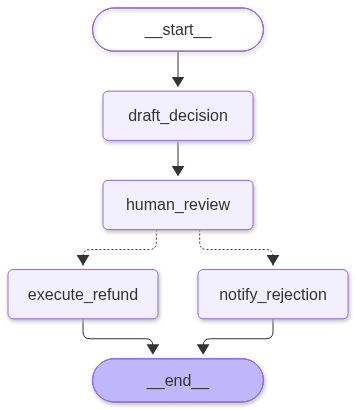

In [10]:
from IPython.display import Image

Image(refund_graph.get_graph().draw_mermaid_png())

With `version="v2"` `invoke` returns a `GraphOutput` with two fields: `.value` (the state) and `.interrupts` (pending questions for a human).

In [11]:
config = {"configurable": {"thread_id": "refund-1"}}
out = refund_graph.invoke(
    {"request": "The headphones I bought 10 days ago stopped working in one ear.", "order_total": 399.0},
    config,
    version="v2",
)
print("paused before:", refund_graph.get_state(config).next)
print("question for a human:", out.interrupts[0].value)

paused before: ('human_review',)
question for a human: {'task': 'Review the refund proposal', 'proposal': {'approve': True, 'amount': 399.0, 'reason': 'The headphones are defective and were purchased within the 30-day return period, so a full refund of the order total is appropriate.'}}


The reviewer decides to refund a different amount (**edit**):

In [12]:
out = refund_graph.invoke(Command(resume={"action": "edit", "amount": 350.0}), config, version="v2")
print(out.value["status"], "| pending interrupts:", out.interrupts)

refunded 350.00 | pending interrupts: ()


And a **reject** on another thread:

In [13]:
config = {"configurable": {"thread_id": "refund-2"}}
refund_graph.invoke({"request": "I want my money back for a laptop I bought 3 months ago, I just don't like it.", "order_total": 4200.0}, config)
out = refund_graph.invoke(Command(resume={"action": "reject", "comment": "outside the 30-day window"}), config, version="v2")
print(out.value["decision"]["reason"])
print(out.value["status"])

The laptop was purchased more than 30 days ago and was not reported as defective.
rejected: outside the 30-day window


### 4.2 Validating human input – interrupt in a loop

A node may call `interrupt()` several times. On every resume the node runs again from the top and the earlier `interrupt()` calls **return their saved answers in order**, so a simple `while` loop keeps asking until the input is valid.

In [14]:
from datetime import date


class DeliveryState(TypedDict, total=False):
    delivery_date: str


def ask_delivery_date(state: DeliveryState) -> DeliveryState:
    question = "Delivery date (YYYY-MM-DD)?"
    while True:
        answer = interrupt(question)
        try:
            return {"delivery_date": date.fromisoformat(answer).isoformat()}
        except ValueError:
            question = f"'{answer}' is not a valid date. Please use YYYY-MM-DD."


delivery_graph = (
    StateGraph(DeliveryState)
    .add_node(ask_delivery_date)
    .add_edge(START, "ask_delivery_date")
    .compile(checkpointer=InMemorySaver())
)

config = {"configurable": {"thread_id": "delivery-1"}}
out = delivery_graph.invoke({}, config, version="v2")
for human_answer in ["next Friday", "2026-13-01", "2026-12-04"]:
    print(f"🤖 {out.interrupts[0].value}\n👤 {human_answer}")
    out = delivery_graph.invoke(Command(resume=human_answer), config, version="v2")
print("✅ saved:", out.value)

🤖 Delivery date (YYYY-MM-DD)?
👤 next Friday
🤖 'next Friday' is not a valid date. Please use YYYY-MM-DD.
👤 2026-13-01
🤖 '2026-13-01' is not a valid date. Please use YYYY-MM-DD.
👤 2026-12-04
✅ saved: {'delivery_date': '2026-12-04'}


### 4.3 ⚠️ The most common pitfall: the node runs again from the top

On resume LangGraph does **not** continue from the line with `interrupt()` – it re-executes the whole node. Any side effect placed *before* `interrupt()` happens twice:

In [15]:
sent_emails = []


def notify_and_ask(state: DeliveryState) -> DeliveryState:
    sent_emails.append("we have received your request")  # ❌ side effect before interrupt()
    answer = interrupt("Approve?")
    return {"delivery_date": answer}


pitfall_graph = (
    StateGraph(DeliveryState)
    .add_node(notify_and_ask)
    .add_edge(START, "notify_and_ask")
    .compile(checkpointer=InMemorySaver())
)
config = {"configurable": {"thread_id": "pitfall"}}
pitfall_graph.invoke({}, config)
pitfall_graph.invoke(Command(resume="2026-12-04"), config)
print("e-mails sent:", len(sent_emails), sent_emails)

e-mails sent: 2 ['we have received your request', 'we have received your request']


**Rules for `interrupt()`:**
1. The graph needs a **checkpointer** and every call a `thread_id`.
2. Put side effects **after** `interrupt()` or in a separate node, and make them idempotent.
3. Don't wrap `interrupt()` in a bare `try/except` – it works by raising a special exception.
4. Keep the order of `interrupt()` calls inside a node deterministic (answers are matched by position).
5. The payload and the resume value must be JSON-serialisable.

### 4.4 Interrupt inside a tool – approval for a risky agent action

`interrupt()` also works inside a **tool** used by an agent. The agent decides on its own *when* to call `issue_refund`, and the tool itself pauses for a human before money leaves the account.

In [16]:
from langchain.agents import create_agent
from langchain.tools import tool

ORDERS = {"A-17": {"item": "headphones", "total": 399.0, "days_ago": 10}}


@tool
def get_order(order_id: str) -> dict:
    """Return order details: item, total and how many days ago it was bought."""
    return ORDERS.get(order_id, {"error": "order not found"})


@tool
def issue_refund(order_id: str, amount: float) -> str:
    """Issue a refund for an order."""
    # the approval step is invisible to the model – it only sees the final tool result
    answer = interrupt({"action": "issue_refund", "order_id": order_id, "amount": amount})
    if answer != "approve":
        return "A human reviewer rejected the refund. Tell the customer it needs manual review."
    return f"Refund of {amount:.2f} for order {order_id} issued."


support_agent = create_agent(
    llm,
    tools=[get_order, issue_refund],
    system_prompt=(
        "You are a support agent. Defective items bought within 30 days get a full refund. "
        "Check the order, and when a refund is justified call issue_refund immediately – do not ask the customer to confirm."
    ),
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "support-1"}}
out = support_agent.invoke(
    {"messages": [{"role": "user", "content": "Order A-17: the headphones are broken, please refund me."}]},
    config,
    version="v2",
)
print("⏸ agent paused inside the tool:", out.interrupts[0].value)

⏸ agent paused inside the tool: {'action': 'issue_refund', 'order_id': 'A-17', 'amount': 399.0}


In [17]:
out = support_agent.invoke(Command(resume="approve"), config, version="v2")
for message in out.value["messages"]:
    message.pretty_print()

================================ Human Message =================================

Order A-17: the headphones are broken, please refund me.
================================== Ai Message ==================================

[{'arguments': '{"order_id":"A-17"}', 'call_id': 'call_49fc3bb46b0d454a9d86d55dfdde4fcf', 'name': 'get_order', 'type': 'function_call', 'id': 'fc_0f0cfc4d0dc97ff3006b098d4a1cd887d2b6aee71e62460755', 'status': 'completed'}]
Tool Calls:
  get_order (call_49fc3bb46b0d454a9d86d55dfdde4fcf)
 Call ID: call_49fc3bb46b0d454a9d86d55dfdde4fcf
  Args:
    order_id: A-17
================================= Tool Message =================================
Name: get_order

{"item": "headphones", "total": 399.0, "days_ago": 10}
================================== Ai Message ==================================

[{'arguments': '{"order_id":"A-17","amount":399.0}', 'call_id': 'call_GhuxG8NO5HAsrtoU01NT2xml', 'name': 'issue_refund', 'type': 'function_call', 'id': 'fc_0f0cfc4d0dc97ff3006b098d4d

### 4.5 Parallel interrupts – reviewing a batch

With `Send` a graph can review several items in parallel. Each branch raises its own interrupt with its own **id**; we answer all of them in one `Command(resume={interrupt_id: answer, ...})`.

In [18]:
from langgraph.types import Send


class BatchState(TypedDict, total=False):
    refunds: list[dict]
    approved: Annotated[list[str], operator.add]


def fan_out(state: BatchState) -> list[Send]:
    return [Send("review_one", refund) for refund in state["refunds"]]


def review_one(refund: dict) -> BatchState:
    decision = interrupt(f"Refund {refund['amount']:.2f} for order {refund['order_id']}?")
    return {"approved": [refund["order_id"]] if decision == "approve" else []}


batch_graph = (
    StateGraph(BatchState)
    .add_node(review_one)
    .add_conditional_edges(START, fan_out, ["review_one"])
    .add_edge("review_one", END)
    .compile(checkpointer=InMemorySaver())
)

config = {"configurable": {"thread_id": "batch-1"}}
refunds = [{"order_id": "A-1", "amount": 50.0}, {"order_id": "A-2", "amount": 2500.0}, {"order_id": "A-3", "amount": 80.0}]
out = batch_graph.invoke({"refunds": refunds}, config, version="v2")
for pending in out.interrupts:
    print(pending.id[:8], pending.value)

# the reviewer approves everything below 1000
answers = {i.id: "approve" if float(i.value.split()[1]) < 1000 else "reject" for i in out.interrupts}
out = batch_graph.invoke(Command(resume=answers), config, version="v2")
print("approved:", sorted(out.value["approved"]))

774cdd14 Refund 80.00 for order A-3?
3b5dad89 Refund 50.00 for order A-1?
0c39b57a Refund 2500.00 for order A-2?
approved: ['A-1', 'A-3']
